# RQ3扩展：Optimised FNN与Boosting residual的Conformal Prediction比较

本Notebook把RQ1选出的两个最终模型分别接入同一套split conformal流程：

- **Optimised FNN**：综合表现均衡、ITE较低；
- **Boosting residual**：72小时RMSE和最差10% cases表现最好。

二者都只用training partition拟合。769个calibration cases只负责估计conformal半径，757个test cases只用于最终评价。

比较问题：

1. 两个模型能否达到90%目标覆盖率？
2. 达到相近coverage时，哪个模型需要更小的预测圆？
3. 在Kuroshio Core中，global与regime-aware校准是否稳定？

> 每个模型必须使用自己的calibration errors。绝不能把原始FNN的conformal半径直接套在新模型上。

In [1]:
from pathlib import Path
import copy, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

PROJECT=next((p for p in [Path.cwd(),*Path.cwd().parents]
              if (p/'data'/'processed').exists()),None)
if PROJECT is None: raise FileNotFoundError('请从data3001-project或其子目录运行。')
PROCESSED=PROJECT/'data'/'processed'; RQ2=PROJECT/'RQ2'; RQ3=PROJECT/'RQ3'
OUT=RQ3/'champion_models'/'output'; OUT.mkdir(parents=True,exist_ok=True)
PARAMS=PROJECT/'output'/'rq1'/'zh'
EARTH_RADIUS_KM=6371.; SEED=3001; TARGET_COVERAGE=.90
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif']=['PingFang SC','Arial Unicode MS','DejaVu Sans']
plt.rcParams['axes.unicode_minus']=False
print('项目目录：',PROJECT); print('输出目录：',OUT)

项目目录： /Users/roger/Documents/data3001-project
输出目录： /Users/roger/Documents/data3001-project/RQ3/champion_models/output


## 1. 重建98维输入和144维目标

输入与RQ1完全一致：起点经纬度，加过去24小时的东西/南北位移和速度。目标是未来72小时相对起点的东西/南北位移。

In [2]:
def latlon_to_local_km(origin_lat,origin_lon,latitude,longitude):
    lat0,lon0=np.deg2rad(origin_lat),np.deg2rad(origin_lon); lat1,lon1=np.deg2rad(latitude),np.deg2rad(longitude)
    dlon=(lon1-lon0+np.pi)%(2*np.pi)-np.pi; dlat=lat1-lat0
    a=np.sin(dlat/2)**2+np.cos(lat0)*np.cos(lat1)*np.sin(dlon/2)**2
    angle=2*np.arcsin(np.sqrt(np.clip(a,0,1)))
    bearing=np.arctan2(np.sin(dlon)*np.cos(lat1),np.cos(lat0)*np.sin(lat1)-np.sin(lat0)*np.cos(lat1)*np.cos(dlon))
    d=EARTH_RADIUS_KM*angle
    return d*np.sin(bearing),d*np.cos(bearing)

def local_km_to_latlon(origin_lat,origin_lon,east,north):
    lat0,lon0=np.deg2rad(origin_lat),np.deg2rad(origin_lon); dist=np.hypot(east,north)
    bearing=np.arctan2(east,north); angular=dist/EARTH_RADIUS_KM
    lat=np.arcsin(np.sin(lat0)*np.cos(angular)+np.cos(lat0)*np.sin(angular)*np.cos(bearing))
    lon=lon0+np.arctan2(np.sin(bearing)*np.sin(angular)*np.cos(lat0),np.cos(angular)-np.sin(lat0)*np.sin(lat))
    return np.rad2deg(lat),(np.rad2deg(lon)+180)%360-180

def haversine_km(lat1,lon1,lat2,lon2):
    lat1,lon1,lat2,lon2=map(np.deg2rad,[lat1,lon1,lat2,lon2])
    a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(np.clip(a,0,1)))

origins=pd.read_parquet(PROCESSED/'forecast_origins.parquet').sort_values('forecast_case_id').reset_index(drop=True)
obs=pd.read_parquet(PROCESSED/'region_A_observations.parquet',columns=['ID','segment_id','segment_step','latitude','longitude','ve','vn'])
n=len(origins)
hist=origins[['forecast_case_id','ID','segment_id','history_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(24)].reset_index(drop=True)
hist['history_index']=np.tile(np.arange(24),n); hist['segment_step']=hist.history_start_step+hist.history_index
hist=hist.merge(obs,on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','history_index']).reset_index(drop=True)
hist['east'],hist['north']=latlon_to_local_km(hist.origin_latitude,hist.origin_longitude,hist.latitude,hist.longitude)
hv=hist[['east','north','ve','vn']].to_numpy().reshape(n,24,4)
X=np.column_stack([origins.origin_latitude,origins.origin_longitude,hv.reshape(n,-1)]).astype(float)

targ=origins[['forecast_case_id','ID','segment_id','target_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(72)].reset_index(drop=True)
targ['lead_time_hours']=np.tile(np.arange(1,73),n); targ['segment_step']=targ.target_start_step+targ.lead_time_hours-1
targ=targ.merge(obs[['ID','segment_id','segment_step','latitude','longitude']],on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','lead_time_hours']).reset_index(drop=True)
targ['east'],targ['north']=latlon_to_local_km(targ.origin_latitude,targ.origin_longitude,targ.latitude,targ.longitude)
Y=targ[['east','north']].to_numpy().reshape(n,144).astype(float)

regimes=pd.read_csv(RQ2/'data'/'forecast_case_regimes.csv').sort_values('forecast_case_id').reset_index(drop=True)
assert regimes.forecast_case_id.equals(origins.forecast_case_id)
hours=np.arange(1,73)[None,:]; lastv=hv[:,-1,2:4]
persistence_Y=np.stack([lastv[:,0,None]*3.6*hours,lastv[:,1,None]*3.6*hours],axis=-1).reshape(n,144)
u=regimes.u_clim.fillna(0).to_numpy(); v=regimes.v_clim.fillna(0).to_numpy()
climatology_Y=np.stack([u[:,None]*3.6*hours,v[:,None]*3.6*hours],axis=-1).reshape(n,144)

env_cont=regimes[['depth_m','u_clim','v_clim','current_speed_clim','distance_to_kuroshio_km']]
env_cat=pd.get_dummies(pd.DataFrame({'regime':regimes.regime.astype(str),'drogue':origins.drogue_status_at_origin.astype(str)}),dtype=float)
X_aug=np.column_stack([X,env_cont.to_numpy(),env_cat.to_numpy()]).astype(float)
train_idx=np.flatnonzero(origins.partition.eq('training')); cal_idx=np.flatnonzero(origins.partition.eq('calibration')); test_idx=np.flatnonzero(origins.partition.eq('test'))
assert X.shape==(5117,98) and Y.shape==(5117,144)
assert (len(train_idx),len(cal_idx),len(test_idx))==(3591,769,757)
assert set(origins.loc[train_idx,'ID']).isdisjoint(set(origins.loc[cal_idx,'ID']))
assert set(origins.loc[train_idx,'ID']).isdisjoint(set(origins.loc[test_idx,'ID']))
print('X/Y:',X.shape,Y.shape,'train/cal/test:',len(train_idx),len(cal_idx),len(test_idx))

X/Y: (5117, 98) (5117, 144) train/cal/test: 3591 769 757


## 2. 固定冠军配置并生成calibration/test预测

这里读取training-CV已经选定的配置，不再用calibration或test重新选择参数。第一次运行会重新拟合并缓存两个模型的预测；之后可直接读取缓存。

In [3]:
def initialise(layer_sizes,rng):
    return [{'W':rng.normal(0,np.sqrt(2/a),(a,b)),'b':np.zeros(b)} for a,b in zip(layer_sizes[:-1],layer_sizes[1:])]
def forward(params,x):
    cur=x
    for j,p in enumerate(params):
        cur=cur@p['W']+p['b']; cur=np.maximum(cur,0) if j<len(params)-1 else cur
    return cur
def loss_grads(params,x,y,l2):
    acts=[x]; zs=[]; cur=x
    for j,p in enumerate(params):
        z=cur@p['W']+p['b']; zs.append(z); cur=np.maximum(z,0) if j<len(params)-1 else z; acts.append(cur)
    delta=2*(cur-y)/(cur-y).size; grads=[None]*len(params)
    for j in range(len(params)-1,-1,-1):
        grads[j]={'W':acts[j].T@delta+2*l2*params[j]['W'],'b':delta.sum(0)}
        if j>0: delta=(delta@params[j]['W'].T)*(zs[j-1]>0)
    return grads
def fit_fnn_final(xraw,yraw,config,epochs,seed):
    xm=xraw.mean(0); xs=xraw.std(0); xs[xs<1e-12]=1
    ym=yraw.mean(0); ys=yraw.std(0); ys[ys<1e-12]=1
    x=(xraw-xm)/xs; y=(yraw-ym)/ys; rng=np.random.default_rng(seed)
    params=initialise((98,*config['hidden_sizes'],144),rng)
    m=[{'W':np.zeros_like(p['W']),'b':np.zeros_like(p['b'])} for p in params]; vv=copy.deepcopy(m); step=0
    for _ in range(epochs):
        permutation=rng.permutation(len(x))
        for start in range(0,len(x),config['batch_size']):
            batch=permutation[start:start+config['batch_size']]
            grads=loss_grads(params,x[batch],y[batch],config['l2']); step+=1
            for j,(p,g) in enumerate(zip(params,grads)):
                for key in ('W','b'):
                    m[j][key]=.9*m[j][key]+.1*g[key]; vv[j][key]=.999*vv[j][key]+.001*g[key]**2
                    p[key]-=config['learning_rate']*(m[j][key]/(1-.9**step))/(np.sqrt(vv[j][key]/(1-.999**step))+1e-8)
    return {'params':params,'xm':xm,'xs':xs,'ym':ym,'ys':ys}
def fnn_predict(model,x): return forward(model['params'],(x-model['xm'])/model['xs'])*model['ys']+model['ym']

def fit_boosting_predict(indices):
    cfg=json.loads((PARAMS/'boosting_residual_best_parameters.json').read_text())
    baseline=persistence_Y
    residual=Y-baseline
    pca=PCA(n_components=cfg['pca_components'],svd_solver='randomized',random_state=SEED).fit(residual[train_idx])
    z=pca.transform(residual[train_idx])
    est=HistGradientBoostingRegressor(loss='squared_error',learning_rate=cfg['learning_rate'],max_iter=cfg['max_iter'],max_leaf_nodes=cfg['max_leaf_nodes'],min_samples_leaf=cfg['min_samples_leaf'],l2_regularization=cfg['l2_regularization'],early_stopping=False,random_state=SEED)
    model=MultiOutputRegressor(est,n_jobs=-1).fit(X_aug[train_idx],z)
    return baseline[indices]+pca.inverse_transform(model.predict(X_aug[indices]))

CACHE=OUT/'champion_calibration_test_predictions.npz'
if CACHE.exists():
    z=np.load(CACHE); fnn_cal=z['fnn_cal']; fnn_test=z['fnn_test']; boost_cal=z['boost_cal']; boost_test=z['boost_test']
    print('读取缓存：',CACHE)
else:
    cfg=json.loads((PARAMS/'optimised_fnn_best_parameters.json').read_text())
    cfg['hidden_sizes']=tuple(cfg['hidden_sizes'])
    cal_members=[]; test_members=[]
    for seed in cfg['ensemble_seeds']:
        model=fit_fnn_final(X[train_idx],Y[train_idx],cfg,cfg['selected_epochs'],seed)
        cal_members.append(fnn_predict(model,X[cal_idx])); test_members.append(fnn_predict(model,X[test_idx]))
    fnn_cal=np.mean(cal_members,axis=0); fnn_test=np.mean(test_members,axis=0)
    boost_cal=fit_boosting_predict(cal_idx); boost_test=fit_boosting_predict(test_idx)
    np.savez_compressed(CACHE,fnn_cal=fnn_cal,fnn_test=fnn_test,boost_cal=boost_cal,boost_test=boost_test)
    print('已保存预测缓存：',CACHE)
print('预测形状：',fnn_cal.shape,fnn_test.shape,boost_cal.shape,boost_test.shape)

读取缓存： /Users/roger/Documents/data3001-project/RQ3/champion_models/output/champion_calibration_test_predictions.npz
预测形状： (769, 144) (757, 144) (769, 144) (757, 144)


## 3. 将轨迹预测转换为逐小时Haversine误差

In [4]:
def prediction_errors(pred,indices):
    pred=pred.reshape(-1,72,2); true=Y[indices].reshape(-1,72,2)
    olat=np.repeat(origins.loc[indices,'origin_latitude'].to_numpy(),72)
    olon=np.repeat(origins.loc[indices,'origin_longitude'].to_numpy(),72)
    plat,plon=local_km_to_latlon(olat,olon,pred[:,:,0].ravel(),pred[:,:,1].ravel())
    tlat,tlon=local_km_to_latlon(olat,olon,true[:,:,0].ravel(),true[:,:,1].ravel())
    return haversine_km(plat,plon,tlat,tlon).reshape(-1,72)

ERRORS={
    'Optimised FNN':{'cal':prediction_errors(fnn_cal,cal_idx),'test':prediction_errors(fnn_test,test_idx)},
    'Boosting residual':{'cal':prediction_errors(boost_cal,cal_idx),'test':prediction_errors(boost_test,test_idx)},
}
for model,e in ERRORS.items():
    print(model,'cal/test 72h RMSE:',np.sqrt(np.mean(e['cal'][:,-1]**2)),np.sqrt(np.mean(e['test'][:,-1]**2)))

# 与RQ1保存的逐case结果按forecast_case_id核对，防止重建预测时发生顺序错位。
audit_files={
    'Optimised FNN':PARAMS/'optimised_fnn_test_case_metrics.csv',
    'Boosting residual':PARAMS/'boosting_residual_test_case_metrics.csv',
}
test_case_ids=origins.loc[test_idx,'forecast_case_id'].to_numpy()
for model,path in audit_files.items():
    saved=pd.read_csv(path).rename(columns={'error_72h_km':'saved_error','final_72h_error_km':'saved_error'})
    rebuilt=pd.DataFrame({'forecast_case_id':test_case_ids,'rebuilt_error':ERRORS[model]['test'][:,-1]})
    check=rebuilt.merge(saved[['forecast_case_id','saved_error']],on='forecast_case_id',validate='one_to_one')
    max_difference=float(np.max(np.abs(check.rebuilt_error-check.saved_error)))
    assert max_difference<1e-6, f'{model}重建误差与RQ1保存结果不一致：{max_difference}'
    print(model,'RQ1逐case误差核对通过；最大差值=',max_difference)

Optimised FNN cal/test 72h RMSE: 64.79616517564577 61.6937569249575
Boosting residual cal/test 72h RMSE: 65.12792522054181 60.76710372291757
Optimised FNN RQ1逐case误差核对通过；最大差值= 5.03419528286031e-12
Boosting residual RQ1逐case误差核对通过；最大差值= 2.842170943040401e-14


## 4. Global与Mondrian conformal校准

对于目标coverage 90%，每个lead time从calibration errors取得有限样本修正后的分位数。预测区域是以模型点预测为圆心、分位数为半径的圆。

- **Global**：所有calibration cases共用同一组逐小时半径；
- **Mondrian**：每个ocean regime分别计算逐小时半径。

In [5]:
def conformal_q(scores,coverage=.9):
    scores=np.sort(np.asarray(scores,float))
    rank=int(np.ceil((len(scores)+1)*coverage))
    return scores[min(rank,len(scores))-1]

REGIMES=['Shelf','Kuroshio Core','Transition','Other Offshore']
cal_reg=regimes.loc[cal_idx,'regime'].to_numpy(); test_reg=regimes.loc[test_idx,'regime'].to_numpy()
rows=[]; lead_rows=[]
for model,e in ERRORS.items():
    global_q=np.array([conformal_q(e['cal'][:,h],TARGET_COVERAGE) for h in range(72)])
    for method in ['Global','Mondrian']:
        for regime in REGIMES:
            cm=cal_reg==regime; tm=test_reg==regime
            q=global_q if method=='Global' else np.array([conformal_q(e['cal'][cm,h],TARGET_COVERAGE) for h in range(72)])
            covered=e['test'][tm]<=q[None,:]
            rows.append({'model':model,'method':method,'regime':regime,'n_calibration':int(cm.sum()),'n_test':int(tm.sum()),
                         'coverage_72h':covered[:,-1].mean(),'radius_72h_km':q[-1],
                         'mean_pointwise_coverage':covered.mean(),'mean_radius_km':q.mean()})
            for h in range(72):
                lead_rows.append({'model':model,'method':method,'regime':regime,'lead_time_hours':h+1,
                                  'coverage':covered[:,h].mean(),'radius_km':q[h]})
result=pd.DataFrame(rows); lead_result=pd.DataFrame(lead_rows)
result.to_csv(OUT/'champion_conformal_regime_summary.csv',index=False)
lead_result.to_csv(OUT/'champion_conformal_by_lead.csv',index=False)
display(result.round(3))

,model,method,regime,n_calibration,n_test,coverage_72h,radius_72h_km,mean_pointwise_coverage,mean_radius_km
0,Optimised FNN,Global,Shelf,200,112,0.973,101.874,0.960,48.391
1,Optimised FNN,Global,Kuroshio Core,120,139,0.806,101.874,0.781,48.391
2,Optimised FNN,Global,Transition,158,165,0.879,101.874,0.882,48.391
3,Optimised FNN,Global,Other Offshore,291,341,0.947,101.874,0.953,48.391
4,Optimised FNN,Mondrian,Shelf,200,112,0.902,61.021,0.916,31.795
5,Optimised FNN,Mondrian,Kuroshio Core,120,139,0.899,139.922,0.890,64.923
6,Optimised FNN,Mondrian,Transition,158,165,0.915,119.754,0.905,53.528
7,Optimised FNN,Mondrian,Other Offshore,291,341,0.933,94.112,0.947,46.196
8,Boosting residual,Global,Shelf,200,112,0.964,103.340,0.951,47.763
9,Boosting residual,Global,Kuroshio Core,120,139,0.799,103.340,0.781,47.763


## 5. 以test drifter为单位的coverage置信区间

半径保持由calibration set固定，只对完整test drifters进行cluster bootstrap。这衡量test drifter抽样波动，不重新选择模型或半径。

In [6]:
test_ids=origins.loc[test_idx,'ID'].to_numpy()
def bootstrap_coverage(model,method,regime,n_boot=2000,seed=2026):
    e=ERRORS[model]; cm=cal_reg==regime; tm=test_reg==regime
    q=np.array([conformal_q(e['cal'][:,h],TARGET_COVERAGE) for h in range(72)]) if method=='Global' else np.array([conformal_q(e['cal'][cm,h],TARGET_COVERAGE) for h in range(72)])
    covered=(e['test'][tm,-1]<=q[-1]).astype(float); ids=test_ids[tm]
    groups={k:covered[ids==k] for k in np.unique(ids)}; keys=np.array(list(groups),dtype=object); rng=np.random.default_rng(seed)
    vals=[]
    for _ in range(n_boot):
        vals.append(np.concatenate([groups[k] for k in rng.choice(keys,len(keys),replace=True)]).mean())
    lo,hi=np.quantile(vals,[.025,.975])
    return {'model':model,'method':method,'regime':regime,'coverage_72h':covered.mean(),'ci_lower':lo,'ci_upper':hi,'n_test_drifters':len(keys),'radius_72h_km':q[-1]}

boot=pd.DataFrame([bootstrap_coverage(m,method,r) for m in ERRORS for method in ['Global','Mondrian'] for r in REGIMES])
boot.to_csv(OUT/'champion_conformal_cluster_bootstrap.csv',index=False)
display(boot.round(3))

,model,method,regime,coverage_72h,ci_lower,ci_upper,n_test_drifters,radius_72h_km
0,Optimised FNN,Global,Shelf,0.973,0.930,1.000,28,101.874
1,Optimised FNN,Global,Kuroshio Core,0.806,0.731,0.870,45,101.874
2,Optimised FNN,Global,Transition,0.879,0.812,0.932,43,101.874
3,Optimised FNN,Global,Other Offshore,0.947,0.921,0.968,41,101.874
4,Optimised FNN,Mondrian,Shelf,0.902,0.837,0.954,28,61.021
5,Optimised FNN,Mondrian,Kuroshio Core,0.899,0.849,0.944,45,139.922
6,Optimised FNN,Mondrian,Transition,0.915,0.857,0.961,43,119.754
7,Optimised FNN,Mondrian,Other Offshore,0.933,0.898,0.958,41,94.112
8,Boosting residual,Global,Shelf,0.964,0.920,0.993,28,103.340
9,Boosting residual,Global,Kuroshio Core,0.799,0.724,0.865,45,103.340


## 6. 可视化coverage与预测区域大小

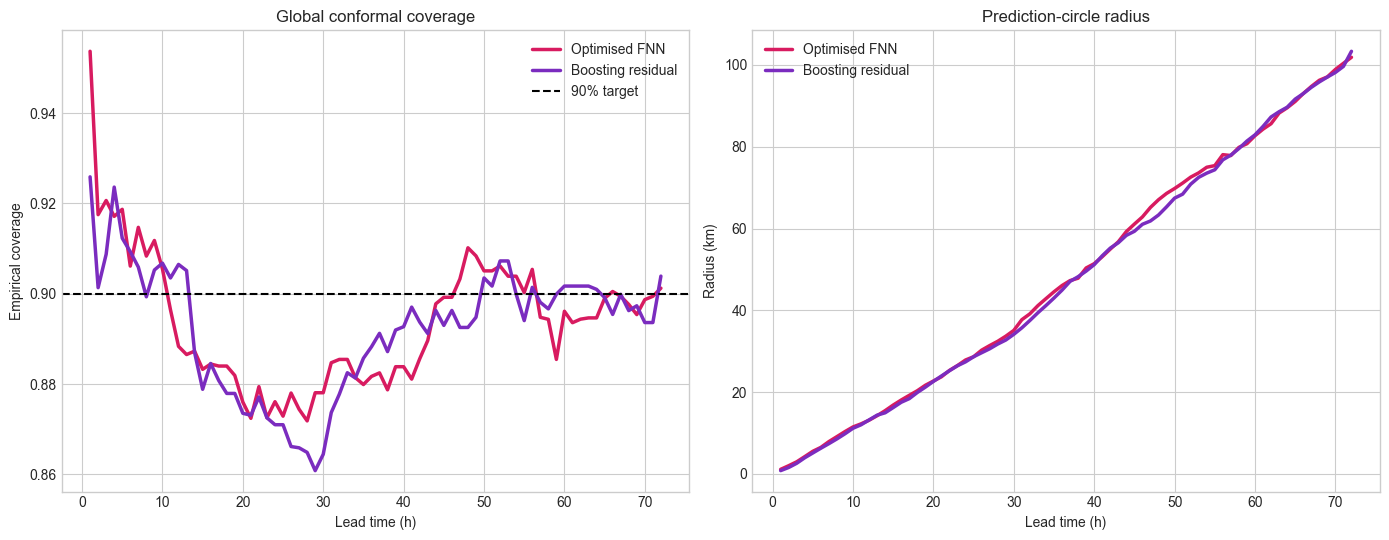

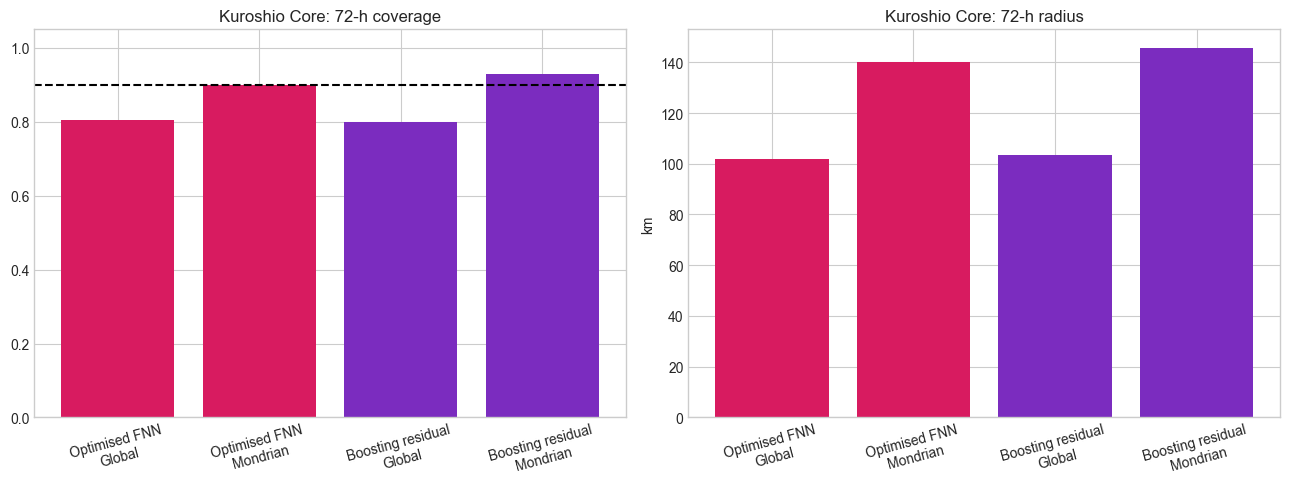

In [7]:
COLORS={'Optimised FNN':'#d81b60','Boosting residual':'#7b2cbf'}
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
for model in ERRORS:
    d=lead_result[(lead_result.model==model)&(lead_result.method=='Global')].groupby('lead_time_hours',as_index=False).agg(coverage=('coverage','mean'),radius_km=('radius_km','mean'))
    axes[0].plot(d.lead_time_hours,d.coverage,label=model,color=COLORS[model],lw=2.5)
    axes[1].plot(d.lead_time_hours,d.radius_km,label=model,color=COLORS[model],lw=2.5)
axes[0].axhline(TARGET_COVERAGE,color='black',ls='--',label='90% target')
axes[0].set(xlabel='Lead time (h)',ylabel='Empirical coverage',title='Global conformal coverage')
axes[1].set(xlabel='Lead time (h)',ylabel='Radius (km)',title='Prediction-circle radius')
axes[0].legend(); axes[1].legend(); fig.tight_layout()
fig.savefig(OUT/'champion_global_coverage_and_radius.png',dpi=200,bbox_inches='tight'); plt.show()

k=result[result.regime.eq('Kuroshio Core')].copy()
labels=k.model+'\n'+k.method
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].bar(labels,k.coverage_72h,color=[COLORS[x] for x in k.model]); axes[0].axhline(.9,color='black',ls='--'); axes[0].set_ylim(0,1.05); axes[0].set_title('Kuroshio Core: 72-h coverage')
axes[1].bar(labels,k.radius_72h_km,color=[COLORS[x] for x in k.model]); axes[1].set_title('Kuroshio Core: 72-h radius'); axes[1].set_ylabel('km')
for ax in axes: ax.tick_params(axis='x',rotation=15)
fig.tight_layout(); fig.savefig(OUT/'champion_kuroshio_conformal.png',dpi=200,bbox_inches='tight'); plt.show()

## 7. 80%、90%和95%目标覆盖率随lead time变化

这一部分复现初始FNN分析中的双面板图，并分别应用于两个冠军模型。左图检查实际coverage是否跟随目标水平；右图显示为了获得更高coverage，需要多大的圆形预测半径。所有分位数都只从各模型自己的769个calibration cases计算。

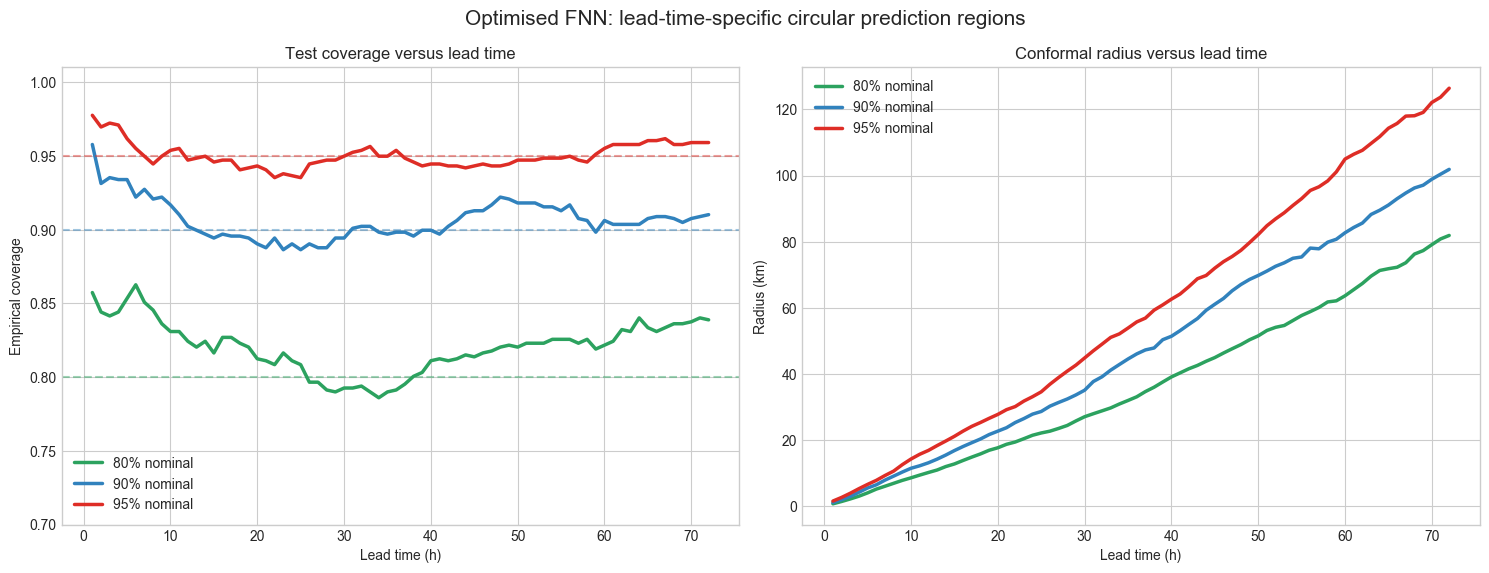

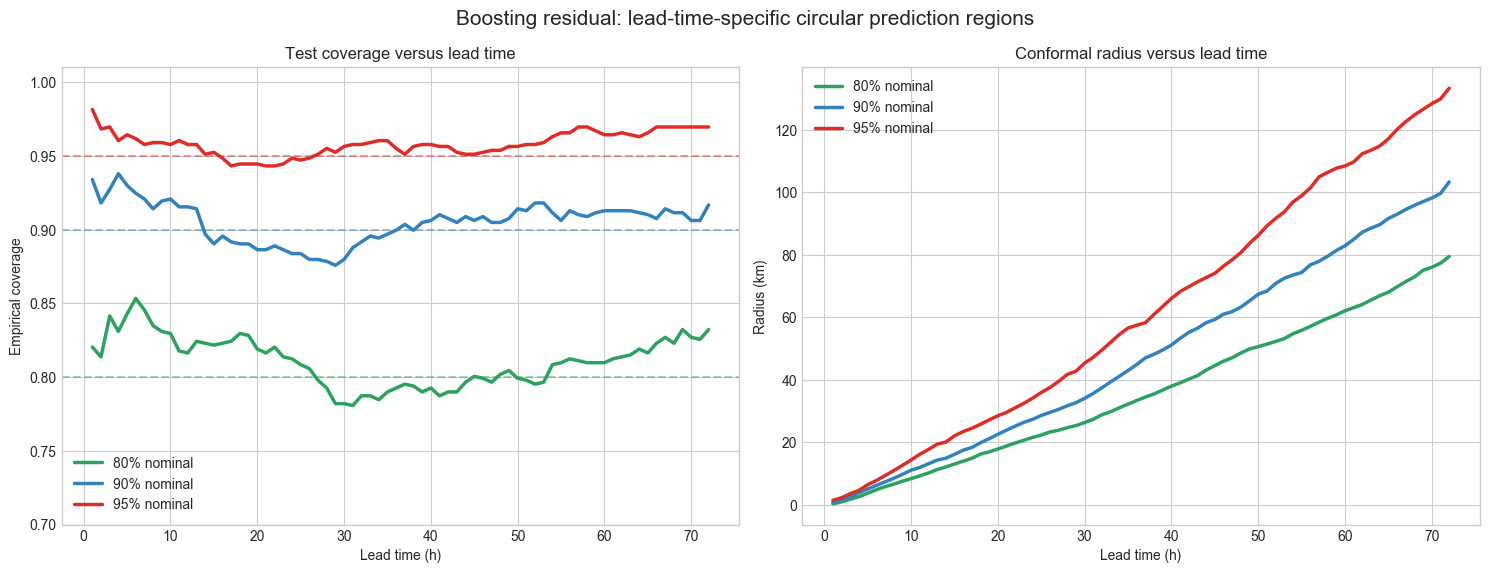

,model,nominal_coverage,empirical_coverage,radius_km
71,Optimised FNN,0.80,0.839,81.887
143,Optimised FNN,0.90,0.910,101.874
215,Optimised FNN,0.95,0.959,126.418
287,Boosting residual,0.80,0.832,79.494
359,Boosting residual,0.90,0.917,103.340
431,Boosting residual,0.95,0.970,133.300


In [8]:
NOMINAL_LEVELS=[.80,.90,.95]
LEVEL_COLORS={.80:'#2ca25f',.90:'#3182bd',.95:'#de2d26'}
multi_rows=[]

for model,e in ERRORS.items():
    for nominal in NOMINAL_LEVELS:
        q=np.array([conformal_q(e['cal'][:,h],nominal) for h in range(72)])
        coverage=np.mean(e['test']<=q[None,:],axis=0)
        for h in range(72):
            multi_rows.append({'model':model,'nominal_coverage':nominal,
                               'lead_time_hours':h+1,'empirical_coverage':coverage[h],
                               'radius_km':q[h]})

multi_nominal=pd.DataFrame(multi_rows)
multi_nominal.to_csv(OUT/'champion_multi_nominal_by_lead.csv',index=False)

for model in ERRORS:
    fig,axes=plt.subplots(1,2,figsize=(15,5.8))
    panel=multi_nominal[multi_nominal.model.eq(model)]
    for nominal in NOMINAL_LEVELS:
        d=panel[panel.nominal_coverage.eq(nominal)].sort_values('lead_time_hours')
        label=f'{int(nominal*100)}% nominal'
        color=LEVEL_COLORS[nominal]
        axes[0].plot(d.lead_time_hours,d.empirical_coverage,color=color,lw=2.5,label=label)
        axes[0].axhline(nominal,color=color,ls='--',alpha=.45)
        axes[1].plot(d.lead_time_hours,d.radius_km,color=color,lw=2.5,label=label)
    axes[0].set(xlabel='Lead time (h)',ylabel='Empirical coverage',
                title='Test coverage versus lead time')
    axes[0].set_ylim(.70,1.01); axes[0].legend(loc='lower left')
    axes[1].set(xlabel='Lead time (h)',ylabel='Radius (km)',
                title='Conformal radius versus lead time')
    axes[1].legend(loc='upper left')
    fig.suptitle(f'{model}: lead-time-specific circular prediction regions',
                 fontsize=15,fontweight='bold')
    fig.tight_layout()
    filename=model.lower().replace(' ','_')+'_multi_nominal_regions.png'
    fig.savefig(OUT/filename,dpi=200,bbox_inches='tight')
    plt.show()

display(multi_nominal[multi_nominal.lead_time_hours.eq(72)]
        [['model','nominal_coverage','empirical_coverage','radius_km']].round(3))

## 8. 自动结论与解释边界

In [9]:
overall=[]
for model,e in ERRORS.items():
    q=np.array([conformal_q(e['cal'][:,h],TARGET_COVERAGE) for h in range(72)])
    overall.append({'model':model,'coverage_72h':np.mean(e['test'][:,-1]<=q[-1]),
                    'radius_72h_km':q[-1],'mean_pointwise_coverage':np.mean(e['test']<=q[None,:]),
                    'mean_radius_km':q.mean()})
overall=pd.DataFrame(overall); overall.to_csv(OUT/'champion_conformal_overall.csv',index=False)
display(overall.round(3))
sharper=overall.loc[overall.radius_72h_km.idxmin()]
kuro=result[(result.regime.eq('Kuroshio Core'))&(result.method.eq('Mondrian'))].sort_values('radius_72h_km')
display(Markdown(f"""
### 当前结果

- 两个模型都用各自的769个calibration-case误差独立校准，没有共用旧FNN半径。
- 90% global conformal下，72小时预测圆更小的是 **{sharper.model}**（半径约 **{sharper.radius_72h_km:.1f} km**）。
- Kuroshio Core采用Mondrian校准后，半径较小的是 **{kuro.iloc[0].model}**；coverage与区间见上表，不能只根据半径判断优劣。
- 若两者coverage相近，半径更小的模型更sharp；若半径很小但coverage不足，则不能称为更可靠。

### 限制

- 同一drifter产生多个相关cases，普通case-exchangeable conformal的严格假设并不完全成立；这里同时报告drifter-cluster bootstrap区间。
- Mondrian方法是看到regime异质性后设计的，应作为探索性扩展披露。
- 本Notebook比较的是不确定性校准，不会改变中心预测本身的RMSE。
"""))

,model,coverage_72h,radius_72h_km,mean_pointwise_coverage,mean_radius_km
0,Optimised FNN,0.910,101.874,0.907,48.391
1,Boosting residual,0.917,103.340,0.905,47.763



### 当前结果

- 两个模型都用各自的769个calibration-case误差独立校准，没有共用旧FNN半径。
- 90% global conformal下，72小时预测圆更小的是 **Optimised FNN**（半径约 **101.9 km**）。
- Kuroshio Core采用Mondrian校准后，半径较小的是 **Optimised FNN**；coverage与区间见上表，不能只根据半径判断优劣。
- 若两者coverage相近，半径更小的模型更sharp；若半径很小但coverage不足，则不能称为更可靠。

### 限制

- 同一drifter产生多个相关cases，普通case-exchangeable conformal的严格假设并不完全成立；这里同时报告drifter-cluster bootstrap区间。
- Mondrian方法是看到regime异质性后设计的，应作为探索性扩展披露。
- 本Notebook比较的是不确定性校准，不会改变中心预测本身的RMSE。
